***Business Understanding***

**Abstract**

The Integrated Household Survey is one of the primary instruments implemented by the Government of Malawi through the National Statistical Office (NSO) roughly every 3-5 years to monitor and evaluate the changing conditions of Malawian households. The IHS data have, among other insights, provided benchmark poverty and vulnerability indicators to foster evidence-based policy formulation and monitor the progress of meeting the Millennium Development Goals (MDGs), the goals listed as part of the Malawi Growth and Development Strategy (MGDS) and now the Sustainable Development Goals (SDGs). 

*Source: https://microdata.worldbank.org/catalog/3818/related-materials*

# ***Loading Libraries***

In [111]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, precision_score, recall_score)
from sklearn.linear_model import LogisticRegression, Ridge, Lasso

tf.keras.utils.set_random_seed(42)   # makes results repeatable 

In [112]:
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [113]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor # regression problem
from sklearn.ensemble import GradientBoostingRegressor # regression problem
from sklearn.ensemble import GradientBoostingClassifier # classification problem
from sklearn.ensemble import AdaBoostClassifier # classification problem
from sklearn.ensemble import AdaBoostRegressor # regression problem
from sklearn.ensemble import RandomForestClassifier # cassification problem
from sklearn.model_selection import train_test_split # we split the data to use it well 
from sklearn.metrics import r2_score, accuracy_score, mean_squared_error, mean_absolute_error
from sklearn.metrics import classification_report,ConfusionMatrixDisplay, confusion_matrix, log_loss
from sklearn.model_selection import GridSearchCV

In [114]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import plot_tree

In [115]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [116]:
import xgboost as xgb
from xgboost import XGBRegressor

In [117]:
%pip install graphviz

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [118]:
from graphviz import Digraph
from sklearn.tree import export_graphviz
from graphviz import Source

***Loading Data***

In [119]:
df = pd.read_csv('Data\\malawi_ihs5_sdg231_plot_dataset.csv')

# ***Data Understanding***

In [120]:
df.head(10)

,case_id,HHID,ea_id,gardenid,plotid,region,district,urban_rural,survey_weight,hhsize,...,slope_pct_area,agro_ecological_zone,harvest_kg,output_value_mwk,share_kg_conversion_factor,all_crops_valued,output_per_labour_day_mwk,log_output_per_labour_day,outlier_1pct,model_ready
0,101011000014,7d78f2c5da59436d9bde9b09ea8a8aaf,10101100,RG02,R01,North,Chitipa,RURAL,93.7194,4,...,3.0,323.0,412.799988,66224.594270,1.0,1,2207.486476,7.699610,0,1
1,101011000023,7144cc6d29b3485d9e6d6188b255c756,10101100,RG02,R01,North,Chitipa,RURAL,93.7194,4,...,3.0,323.0,1066.768002,169000.000000,0.5,1,1207.142857,7.096012,0,1
2,101011000023,7144cc6d29b3485d9e6d6188b255c756,10101100,RG02,R02,North,Chitipa,RURAL,93.7194,4,...,3.0,323.0,40.799999,11099.684986,1.0,1,231.243437,5.443471,0,1
3,101011000040,9936d103bf974a93afbc63d477b8b3f2,10101100,RG02,R01,North,Chitipa,RURAL,93.7194,4,...,3.0,323.0,171.449997,29363.874209,1.0,1,4194.839173,8.341610,0,1
4,101011000071,cc8f211413cd493e83e01a96aba95bbb,10101100,RG02,R01,North,Chitipa,RURAL,93.7194,5,...,3.0,323.0,619.199982,99336.891405,1.0,1,4139.037142,8.328218,0,1
5,101011000071,cc8f211413cd493e83e01a96aba95bbb,10101100,RG01,R01,North,Chitipa,RURAL,93.7194,5,...,3.0,323.0,154.799995,36955.478825,1.0,1,1421.364570,7.259373,0,1
6,101011000071,cc8f211413cd493e83e01a96aba95bbb,10101100,RG02,R02,North,Chitipa,RURAL,93.7194,5,...,3.0,323.0,358.499994,97530.320546,1.0,1,2786.580587,7.932571,0,1
7,101011000071,cc8f211413cd493e83e01a96aba95bbb,10101100,RG01,R02,North,Chitipa,RURAL,93.7194,5,...,3.0,323.0,4.400000,2200.000048,1.0,1,366.666675,5.904453,0,1
8,101011000095,e50cfa8d11b44d56891e0fad015b07c7,10101100,RG02,R01,North,Chitipa,RURAL,93.7194,5,...,3.0,323.0,NaN,NaN,0.0,0,NaN,NaN,0,0
9,101011000095,e50cfa8d11b44d56891e0fad015b07c7,10101100,RG03,R01,North,Chitipa,RURAL,93.7194,5,...,3.0,323.0,NaN,NaN,0.0,0,NaN,NaN,0,0


In [121]:
df.describe(include='object')

C:\Users\Mwangi Maina\AppData\Local\Temp\ipykernel_10220\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,HHID,gardenid,plotid,region,district,urban_rural,manager_sex,manager_relation,area_source,main_crop_reported,main_crop_by_value,soil_type,soil_quality,slope_reported,erosion_control
count,17180,17180,17180,17180,17180,17180,17180,17180,17180,17177,17177,17180,17180,17180,17179
unique,8772,13,9,3,32,2,2,11,2,49,49,4,3,4,9
top,53e1255315534be3977b82e5fbdd8da9,RG02,R01,Southern,Lilongwe,RURAL,MALE,HEAD,GPS,MAIZE LOCAL,MAIZE LOCAL,Between sandy & clay,Good,Flat,No erosion control
freq,11,9063,14370,8009,890,16096,10185,14836,16081,6277,5466,9301,9600,10118,10170


In [122]:
rows, columns = df.shape
print(f"The Malawi Integrated Household Survey (IHS) dataset has {rows} rows and {columns} columns.")

The Malawi Integrated Household Survey (IHS) dataset has 17180 rows and 59 columns.


In [123]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17180 entries, 0 to 17179
Data columns (total 59 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   case_id                     17180 non-null  int64  
 1   HHID                        17180 non-null  str    
 2   ea_id                       17180 non-null  int64  
 3   gardenid                    17180 non-null  str    
 4   plotid                      17180 non-null  str    
 5   region                      17180 non-null  str    
 6   district                    17180 non-null  str    
 7   urban_rural                 17180 non-null  str    
 8   survey_weight               17180 non-null  float64
 9   hhsize                      17180 non-null  int64  
 10  manager_pid                 17180 non-null  float64
 11  manager_sex                 17180 non-null  str    
 12  manager_age                 17180 non-null  int64  
 13  manager_relation            17180 non-null

# ***Data Preparation***

In [124]:
columns = tuple(df.columns.tolist())

In [125]:
columns

('case_id',
 'HHID',
 'ea_id',
 'gardenid',
 'plotid',
 'region',
 'district',
 'urban_rural',
 'survey_weight',
 'hhsize',
 'manager_pid',
 'manager_sex',
 'manager_age',
 'manager_relation',
 'area_ha',
 'area_source',
 'hh_farm_area_ha',
 'small_scale',
 'main_crop_reported',
 'main_crop_by_value',
 'n_crops',
 'soil_type',
 'soil_quality',
 'slope_reported',
 'erosion_control',
 'irrigated',
 'organic_fert_used',
 'inorganic_fert_used',
 'inorganic_fert_kg',
 'pesticide_used',
 'labour_days_family',
 'labour_days_hired',
 'labour_days_exchange',
 'labour_days_free',
 'labour_days_total',
 'plot_wetness_index',
 'plot_elevation_m',
 'plot_slope_pct',
 'plot_dist_household_km',
 'hh_dist_road_km',
 'hh_dist_market_km',
 'hh_dist_admarc_km',
 'hh_dist_popcenter_km',
 'pop_density',
 'rain_annual_avg_mm',
 'rain_2019_mm',
 'ndvi_avg',
 'ndvi_2019',
 'elevation_m',
 'slope_pct_area',
 'agro_ecological_zone',
 'harvest_kg',
 'output_value_mwk',
 'share_kg_conversion_factor',
 'all_crops_

In [126]:
df_cleaner = df.drop(columns=['case_id',
 'HHID',
 'ea_id',
 'gardenid',
 'plotid',
 'region',
 'district',
 'urban_rural',
 'survey_weight',
 'hhsize',
 'manager_pid',
 'manager_sex',
 'manager_age',
 'manager_relation',
 'area_ha',
 'area_source','soil_type',
 'soil_quality',
 'slope_reported',
 'erosion_control','plot_wetness_index',
 'plot_elevation_m',
 'plot_slope_pct','ndvi_avg',
 'ndvi_2019',
 'elevation_m',
 'slope_pct_area',
 'agro_ecological_zone','model_ready','main_crop_reported',
 'main_crop_by_value','outlier_1pct'])

In [127]:
df_cleaner.shape

(17180, 27)

In [128]:
df_cleaner.head(10)

,hh_farm_area_ha,small_scale,n_crops,irrigated,organic_fert_used,inorganic_fert_used,inorganic_fert_kg,pesticide_used,labour_days_family,labour_days_hired,...,hh_dist_popcenter_km,pop_density,rain_annual_avg_mm,rain_2019_mm,harvest_kg,output_value_mwk,share_kg_conversion_factor,all_crops_valued,output_per_labour_day_mwk,log_output_per_labour_day
0,0.453248,0,1.0,0,0,1,25.0,0,30.0,0.0,...,4.1,610.0,1007.0,1158.0,412.799988,66224.594270,1.0,1,2207.486476,7.699610
1,0.655591,0,2.0,0,0,1,150.0,0,140.0,0.0,...,4.1,610.0,1007.0,1158.0,1066.768002,169000.000000,0.5,1,1207.142857,7.096012
2,0.655591,0,1.0,0,0,0,0.0,0,48.0,0.0,...,4.1,610.0,1007.0,1158.0,40.799999,11099.684986,1.0,1,231.243437,5.443471
3,0.485623,0,2.0,0,0,1,20.0,0,7.0,0.0,...,4.1,610.0,1007.0,1158.0,171.449997,29363.874209,1.0,1,4194.839173,8.341610
4,1.157402,0,1.0,0,0,1,100.0,0,24.0,0.0,...,4.1,610.0,1007.0,1158.0,619.199982,99336.891405,1.0,1,4139.037142,8.328218
5,1.157402,0,1.0,0,0,0,0.0,0,18.0,8.0,...,4.1,610.0,1007.0,1158.0,154.799995,36955.478825,1.0,1,1421.364570,7.259373
6,1.157402,0,1.0,0,0,0,0.0,0,35.0,0.0,...,4.1,610.0,1007.0,1158.0,358.499994,97530.320546,1.0,1,2786.580587,7.932571
7,1.157402,0,1.0,0,0,0,0.0,0,6.0,0.0,...,4.1,610.0,1007.0,1158.0,4.400000,2200.000048,1.0,1,366.666675,5.904453
8,0.501811,0,1.0,0,0,1,10.0,0,48.0,0.0,...,4.1,610.0,1007.0,1158.0,NaN,NaN,0.0,0,NaN,NaN
9,0.501811,0,2.0,0,0,0,0.0,0,47.0,0.0,...,4.1,610.0,1007.0,1158.0,NaN,NaN,0.0,0,NaN,NaN


In [129]:
df_clean = df_cleaner.dropna()

In [130]:
df_clean.shape

(15326, 27)

In [131]:
df_clean.head()

,hh_farm_area_ha,small_scale,n_crops,irrigated,organic_fert_used,inorganic_fert_used,inorganic_fert_kg,pesticide_used,labour_days_family,labour_days_hired,...,hh_dist_popcenter_km,pop_density,rain_annual_avg_mm,rain_2019_mm,harvest_kg,output_value_mwk,share_kg_conversion_factor,all_crops_valued,output_per_labour_day_mwk,log_output_per_labour_day
0,0.453248,0,1.0,0,0,1,25.0,0,30.0,0.0,...,4.1,610.0,1007.0,1158.0,412.799988,66224.594270,1.0,1,2207.486476,7.699610
1,0.655591,0,2.0,0,0,1,150.0,0,140.0,0.0,...,4.1,610.0,1007.0,1158.0,1066.768002,169000.000000,0.5,1,1207.142857,7.096012
2,0.655591,0,1.0,0,0,0,0.0,0,48.0,0.0,...,4.1,610.0,1007.0,1158.0,40.799999,11099.684986,1.0,1,231.243437,5.443471
3,0.485623,0,2.0,0,0,1,20.0,0,7.0,0.0,...,4.1,610.0,1007.0,1158.0,171.449997,29363.874209,1.0,1,4194.839173,8.341610
4,1.157402,0,1.0,0,0,1,100.0,0,24.0,0.0,...,4.1,610.0,1007.0,1158.0,619.199982,99336.891405,1.0,1,4139.037142,8.328218


In [132]:
print(df_clean.dtypes)

hh_farm_area_ha               float64
small_scale                     int64
n_crops                       float64
irrigated                       int64
organic_fert_used               int64
inorganic_fert_used             int64
inorganic_fert_kg             float64
pesticide_used                  int64
labour_days_family            float64
labour_days_hired             float64
labour_days_exchange          float64
labour_days_free              float64
labour_days_total             float64
plot_dist_household_km        float64
hh_dist_road_km               float64
hh_dist_market_km             float64
hh_dist_admarc_km             float64
hh_dist_popcenter_km          float64
pop_density                   float64
rain_annual_avg_mm            float64
rain_2019_mm                  float64
harvest_kg                    float64
output_value_mwk              float64
share_kg_conversion_factor    float64
all_crops_valued                int64
output_per_labour_day_mwk     float64
log_output_p

In [133]:
df_clean["rain_annual_avg_mm"].nunique()

282

# ***Data Understanding***

In [134]:
# shape - rows adn columns
# descriptive stats
# cehck for missing values
# check for duplicates
# univariable analysis
# bivariate analysis
# mutlivariate analysis

class DataUnderstanding:
    #  intialization
    def __init__(self, df):
        self.df = df 

    def get_shape(self) -> str:
        row, column = self.df.shape
        output = f"Records: {row} & Features: {column}"
        return output

    def descriptive_stats(self):
        display(self.df.describe())
    
    def univarite_analysis(self):
        columns = self.df.columns 
        for feature in columns:
            print("="*50)
            print(f"** - {feature} - **")
            display(self.df[feature].describe())
            print("="*50)

In [135]:
data_understanding = DataUnderstanding(df)

data_understanding.get_shape()


'Records: 17180 & Features: 59'

In [136]:
data_understanding.descriptive_stats()

,case_id,ea_id,survey_weight,hhsize,manager_pid,manager_age,area_ha,hh_farm_area_ha,small_scale,n_crops,...,slope_pct_area,agro_ecological_zone,harvest_kg,output_value_mwk,share_kg_conversion_factor,all_crops_valued,output_per_labour_day_mwk,log_output_per_labour_day,outlier_1pct,model_ready
count,1.718000e+04,1.718000e+04,17180.000000,17180.000000,17180.000000,17180.000000,17155.000000,17180.000000,17180.000000,17177.000000,...,17167.000000,17167.000000,1.675400e+04,1.670600e+04,17177.000000,17180.000000,1.669800e+04,16385.000000,17180.000000,17180.000000
mean,2.366078e+11,2.366078e+07,375.008518,4.744179,1.164901,44.572468,0.327453,0.808995,0.298312,1.900856,...,6.671113,314.409798,9.176517e+02,1.657874e+05,0.756845,0.907276,4.055118e+03,6.661202,0.017811,0.870373
std,7.420161e+10,7.420161e+06,230.518096,2.050056,0.476946,15.807903,0.318244,0.764943,0.457530,0.998606,...,5.205400,4.003582,3.222044e+04,5.661081e+06,0.358359,0.290054,1.868536e+05,1.171078,0.132269,0.335903
min,1.010110e+11,1.010110e+07,22.499932,1.000000,1.000000,0.000000,0.000300,0.000000,0.000000,1.000000,...,0.000000,312.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.098723,0.000000,0.000000
25%,2.030329e+11,2.030329e+07,202.052306,3.000000,1.000000,32.000000,0.121406,0.348030,0.000000,1.000000,...,2.000000,312.000000,1.020000e+02,1.637751e+04,0.500000,1.000000,3.733669e+02,5.970630,0.000000,1.000000
50%,2.090544e+11,2.090544e+07,335.676499,5.000000,1.000000,42.000000,0.242812,0.607029,0.000000,2.000000,...,5.000000,313.000000,2.200000e+02,3.627037e+04,1.000000,1.000000,7.790791e+02,6.681482,0.000000,1.000000
75%,3.070462e+11,3.070462e+07,490.356833,6.000000,1.000000,55.000000,0.420873,1.023856,1.000000,3.000000,...,10.000000,313.000000,4.500000e+02,7.500000e+04,1.000000,1.000000,1.593685e+03,7.390659,0.000000,1.000000
max,3.155382e+11,3.155382e+07,1855.510883,22.000000,10.000000,99.000000,6.564007,8.381047,1.000000,5.000000,...,29.000000,323.000000,2.800052e+06,4.321359e+08,1.000000,1.000000,2.160680e+07,16.888518,1.000000,1.000000


In [137]:
data_understanding.univarite_analysis()

** - case_id - **


count    1.718000e+04
mean     2.366078e+11
std      7.420161e+10
min      1.010110e+11
25%      2.030329e+11
50%      2.090544e+11
75%      3.070462e+11
max      3.155382e+11
Name: case_id, dtype: float64

** - HHID - **


count                                17180
unique                                8772
top       53e1255315534be3977b82e5fbdd8da9
freq                                    11
Name: HHID, dtype: object

** - ea_id - **


count    1.718000e+04
mean     2.366078e+07
std      7.420161e+06
min      1.010110e+07
25%      2.030329e+07
50%      2.090544e+07
75%      3.070462e+07
max      3.155382e+07
Name: ea_id, dtype: float64

** - gardenid - **


count     17180
unique       13
top        RG02
freq       9063
Name: gardenid, dtype: object

** - plotid - **


count     17180
unique        9
top         R01
freq      14370
Name: plotid, dtype: object

** - region - **


count        17180
unique           3
top       Southern
freq          8009
Name: region, dtype: object

** - district - **


count        17180
unique          32
top       Lilongwe
freq           890
Name: district, dtype: object

** - urban_rural - **


count     17180
unique        2
top       RURAL
freq      16096
Name: urban_rural, dtype: object

** - survey_weight - **


count    17180.000000
mean       375.008518
std        230.518096
min         22.499932
25%        202.052306
50%        335.676499
75%        490.356833
max       1855.510883
Name: survey_weight, dtype: float64

** - hhsize - **


count    17180.000000
mean         4.744179
std          2.050056
min          1.000000
25%          3.000000
50%          5.000000
75%          6.000000
max         22.000000
Name: hhsize, dtype: float64

** - manager_pid - **


count    17180.000000
mean         1.164901
std          0.476946
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         10.000000
Name: manager_pid, dtype: float64

** - manager_sex - **


count     17180
unique        2
top        MALE
freq      10185
Name: manager_sex, dtype: object

** - manager_age - **


count    17180.000000
mean        44.572468
std         15.807903
min          0.000000
25%         32.000000
50%         42.000000
75%         55.000000
max         99.000000
Name: manager_age, dtype: float64

** - manager_relation - **


count     17180
unique       11
top        HEAD
freq      14836
Name: manager_relation, dtype: object

** - area_ha - **


count    17155.000000
mean         0.327453
std          0.318244
min          0.000300
25%          0.121406
50%          0.242812
75%          0.420873
max          6.564007
Name: area_ha, dtype: float64

** - area_source - **


count     17180
unique        2
top         GPS
freq      16081
Name: area_source, dtype: object

** - hh_farm_area_ha - **


count    17180.000000
mean         0.808995
std          0.764943
min          0.000000
25%          0.348030
50%          0.607029
75%          1.023856
max          8.381047
Name: hh_farm_area_ha, dtype: float64

** - small_scale - **


count    17180.000000
mean         0.298312
std          0.457530
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max          1.000000
Name: small_scale, dtype: float64

** - main_crop_reported - **


count           17177
unique             49
top       MAIZE LOCAL
freq             6277
Name: main_crop_reported, dtype: object

** - main_crop_by_value - **


count           17177
unique             49
top       MAIZE LOCAL
freq             5466
Name: main_crop_by_value, dtype: object

** - n_crops - **


count    17177.000000
mean         1.900856
std          0.998606
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max          5.000000
Name: n_crops, dtype: float64

** - soil_type - **


count                    17180
unique                       4
top       Between sandy & clay
freq                      9301
Name: soil_type, dtype: object

** - soil_quality - **


count     17180
unique        3
top        Good
freq       9600
Name: soil_quality, dtype: object

** - slope_reported - **


count     17180
unique        4
top        Flat
freq      10118
Name: slope_reported, dtype: object

** - erosion_control - **


count                  17179
unique                     9
top       No erosion control
freq                   10170
Name: erosion_control, dtype: object

** - irrigated - **


count    17180.000000
mean         0.005821
std          0.076074
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: irrigated, dtype: float64

** - organic_fert_used - **


count    17180.000000
mean         0.208440
std          0.406205
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: organic_fert_used, dtype: float64

** - inorganic_fert_used - **


count    17180.000000
mean         0.500698
std          0.500014
min          0.000000
25%          0.000000
50%          1.000000
75%          1.000000
max          1.000000
Name: inorganic_fert_used, dtype: float64

** - inorganic_fert_kg - **


count    17180.000000
mean        45.671002
std        250.894847
min          0.000000
25%          0.000000
50%          0.000000
75%         50.000000
max      10200.000000
Name: inorganic_fert_kg, dtype: float64

** - pesticide_used - **


count    17180.000000
mean         0.052328
std          0.222695
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: pesticide_used, dtype: float64

** - labour_days_family - **


count    17180.000000
mean        58.456810
std         55.593751
min          0.000000
25%         24.000000
50%         45.000000
75%         76.000000
max       2432.000000
Name: labour_days_family, dtype: float64

** - labour_days_hired - **


count    17180.000000
mean         4.862107
std        174.784298
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max      15000.000000
Name: labour_days_hired, dtype: float64

** - labour_days_exchange - **


count    17180.000000
mean         3.553725
std        201.341815
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max      25000.000000
Name: labour_days_exchange, dtype: float64

** - labour_days_free - **


count    17180.000000
mean         1.238941
std         50.407624
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       5000.000000
Name: labour_days_free, dtype: float64

** - labour_days_total - **


count    17180.000000
mean        68.111583
std        276.750324
min          0.000000
25%         27.000000
50%         49.000000
75%         80.000000
max      25030.000000
Name: labour_days_total, dtype: float64

** - plot_wetness_index - **


count    16045.000000
mean        14.142848
std          3.683913
min          0.000000
25%         12.000000
50%         13.000000
75%         15.000000
max         36.000000
Name: plot_wetness_index, dtype: float64

** - plot_elevation_m - **


count    16033.000000
mean       881.340173
std        328.567415
min         33.000000
25%        631.000000
50%        851.000000
75%       1160.000000
max       1803.000000
Name: plot_elevation_m, dtype: float64

** - plot_slope_pct - **


count    16033.000000
mean         4.944427
std          5.239436
min          0.000000
25%          2.000000
50%          3.000000
75%          6.000000
max         52.000000
Name: plot_slope_pct, dtype: float64

** - plot_dist_household_km - **


count    16045.000000
mean         1.279900
std          4.742543
min          0.000000
25%          0.100000
50%          0.400000
75%          1.000000
max         98.900002
Name: plot_dist_household_km, dtype: float64

** - hh_dist_road_km - **


count    17167.000000
mean        10.180358
std         10.813701
min          0.000000
25%          2.300000
50%          6.700000
75%         14.400000
max         63.799999
Name: hh_dist_road_km, dtype: float64

** - hh_dist_market_km - **


count    17167.000000
mean        23.858344
std         13.686322
min          0.200000
25%         13.500000
50%         22.100000
75%         32.599998
max        102.099998
Name: hh_dist_market_km, dtype: float64

** - hh_dist_admarc_km - **


count    17167.000000
mean         8.628025
std          6.200495
min          0.300000
25%          4.500000
50%          7.500000
75%         11.700000
max         69.400002
Name: hh_dist_admarc_km, dtype: float64

** - hh_dist_popcenter_km - **


count    17167.000000
mean        22.178138
std         13.636977
min          0.200000
25%         12.100000
50%         19.700001
75%         30.500000
max         71.199997
Name: hh_dist_popcenter_km, dtype: float64

** - pop_density - **


count    17167.000000
mean       428.392264
std        936.123468
min         20.000000
25%        150.000000
50%        240.000000
75%        380.000000
max      13000.000000
Name: pop_density, dtype: float64

** - rain_annual_avg_mm - **


count    17167.000000
mean       839.807945
std         94.119200
min        614.000000
25%        795.000000
50%        814.000000
75%        857.000000
max       1233.000000
Name: rain_annual_avg_mm, dtype: float64

** - rain_2019_mm - **


count    17167.000000
mean      1043.086387
std        107.676247
min        851.000000
25%        969.000000
50%       1032.000000
75%       1085.000000
max       1678.000000
Name: rain_2019_mm, dtype: float64

** - ndvi_avg - **


count    17167.000000
mean         0.205365
std          0.040113
min          0.002000
25%          0.184000
50%          0.204000
75%          0.228000
max          0.362000
Name: ndvi_avg, dtype: float64

** - ndvi_2019 - **


count    17167.000000
mean         0.146132
std          0.029097
min          0.000000
25%          0.128000
50%          0.143000
75%          0.161000
max          0.257000
Name: ndvi_2019, dtype: float64

** - elevation_m - **


count    17167.000000
mean       888.208481
std        330.155115
min         37.000000
25%        632.000000
50%        883.000000
75%       1156.000000
max       1652.000000
Name: elevation_m, dtype: float64

** - slope_pct_area - **


count    17167.000000
mean         6.671113
std          5.205400
min          0.000000
25%          2.000000
50%          5.000000
75%         10.000000
max         29.000000
Name: slope_pct_area, dtype: float64

** - agro_ecological_zone - **


count    17167.000000
mean       314.409798
std          4.003582
min        312.000000
25%        312.000000
50%        313.000000
75%        313.000000
max        323.000000
Name: agro_ecological_zone, dtype: float64

** - harvest_kg - **


count    1.675400e+04
mean     9.176517e+02
std      3.222044e+04
min      0.000000e+00
25%      1.020000e+02
50%      2.200000e+02
75%      4.500000e+02
max      2.800052e+06
Name: harvest_kg, dtype: float64

** - output_value_mwk - **


count    1.670600e+04
mean     1.657874e+05
std      5.661081e+06
min      0.000000e+00
25%      1.637751e+04
50%      3.627037e+04
75%      7.500000e+04
max      4.321359e+08
Name: output_value_mwk, dtype: float64

** - share_kg_conversion_factor - **


count    17177.000000
mean         0.756845
std          0.358359
min          0.000000
25%          0.500000
50%          1.000000
75%          1.000000
max          1.000000
Name: share_kg_conversion_factor, dtype: float64

** - all_crops_valued - **


count    17180.000000
mean         0.907276
std          0.290054
min          0.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          1.000000
Name: all_crops_valued, dtype: float64

** - output_per_labour_day_mwk - **


count    1.669800e+04
mean     4.055118e+03
std      1.868536e+05
min      0.000000e+00
25%      3.733669e+02
50%      7.790791e+02
75%      1.593685e+03
max      2.160680e+07
Name: output_per_labour_day_mwk, dtype: float64

** - log_output_per_labour_day - **


count    16385.000000
mean         6.661202
std          1.171078
min          0.098723
25%          5.970630
50%          6.681482
75%          7.390659
max         16.888518
Name: log_output_per_labour_day, dtype: float64

** - outlier_1pct - **


count    17180.000000
mean         0.017811
std          0.132269
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: outlier_1pct, dtype: float64

** - model_ready - **


count    17180.000000
mean         0.870373
std          0.335903
min          0.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          1.000000
Name: model_ready, dtype: float64

In [138]:
df_final = df_clean.drop(columns=['output_per_labour_day_mwk', 'output_value_mwk', 'harvest_kg', 'labour_days_total', 'all_crops_valued', 'share_kg_conversion_factor'])

In [139]:
rows, columns = df_final.shape
print(f"The final Malawi Integrated Household Survey (IHS) dataset has {rows} rows and {columns} columns.")

The final Malawi Integrated Household Survey (IHS) dataset has 15326 rows and 21 columns.


In [140]:
print(df_final.dtypes)

hh_farm_area_ha              float64
small_scale                    int64
n_crops                      float64
irrigated                      int64
organic_fert_used              int64
inorganic_fert_used            int64
inorganic_fert_kg            float64
pesticide_used                 int64
labour_days_family           float64
labour_days_hired            float64
labour_days_exchange         float64
labour_days_free             float64
plot_dist_household_km       float64
hh_dist_road_km              float64
hh_dist_market_km            float64
hh_dist_admarc_km            float64
hh_dist_popcenter_km         float64
pop_density                  float64
rain_annual_avg_mm           float64
rain_2019_mm                 float64
log_output_per_labour_day    float64
dtype: object


***Bivariate Analysis***

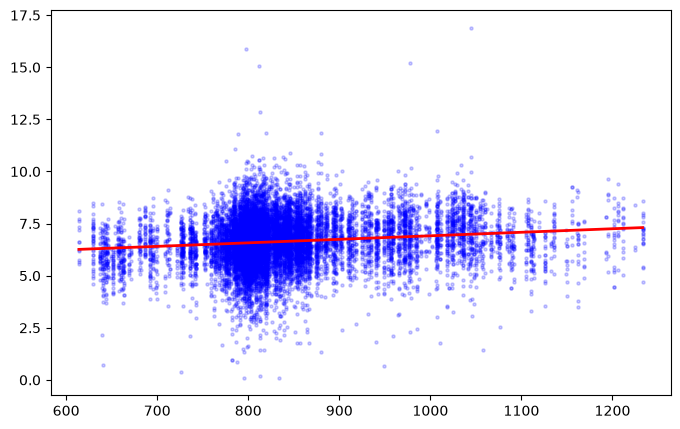

In [141]:
X1 = df_final["rain_annual_avg_mm"]
y = df_final["log_output_per_labour_day"]

plt.figure(figsize=(8, 5))
plt.scatter(X1, y, s=5, alpha=0.2, color="blue")

m, b = np.polyfit(X1, y, 1)
xs = np.linspace(X1.min(), X1.max(), 100)
plt.plot(xs, m * xs + b, color="red", linewidth=2,
         label=f"Trend (r = {np.corrcoef(X1, y)[0,1]:.2f})")

***Multi-variate Analysis***

In [142]:
X = df_final.drop(columns="log_output_per_labour_day").astype("float32")   
y = df_final["log_output_per_labour_day"]                           

feature_names = X.columns
X = X.values

# print("X shape:", X.shape, " -> (customers, features)")
# print("y shape:", y.shape)

In [143]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)

print("Train:", X_train.shape, y_train.shape)
print("Test: ", X_test.shape,  y_test.shape)

Train: (12260, 20) (12260,)
Test:  (3066, 20) (3066,)


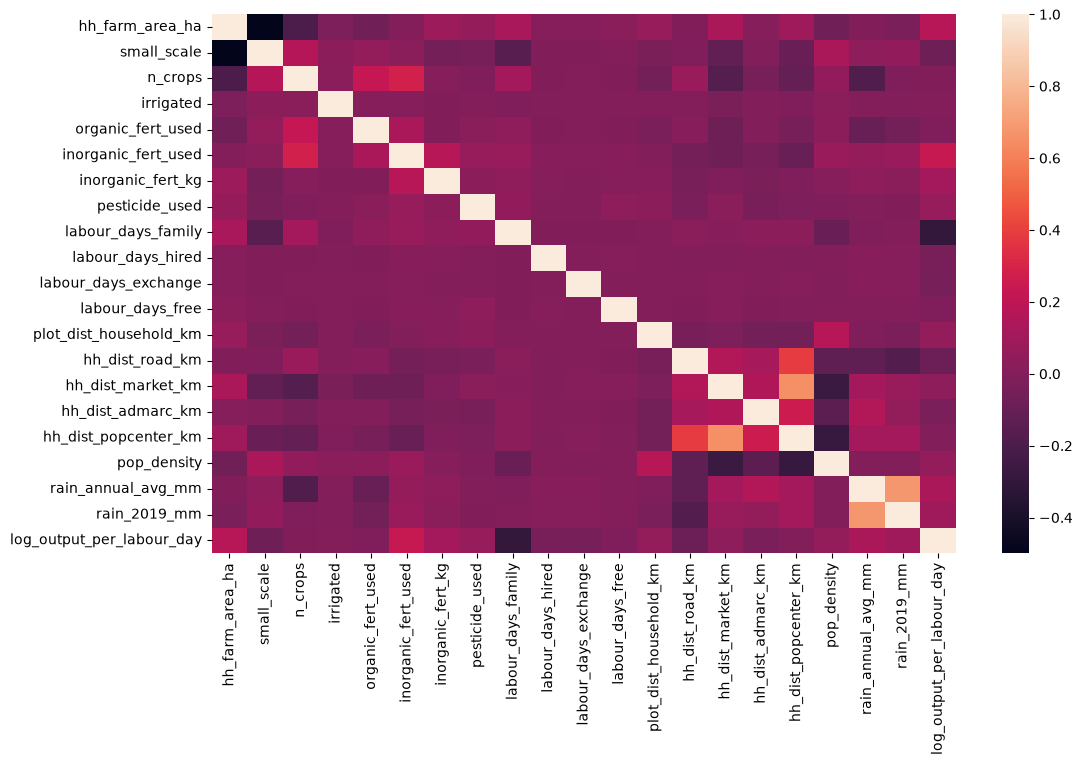

In [144]:
fig, ax = plt.subplots(figsize=(12, 7))

sns.heatmap(df_final.corr())#, annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
plt.show()

# ***Modelling***

***Modelling: KMeans***

In [145]:
df_final.head()

,hh_farm_area_ha,small_scale,n_crops,irrigated,organic_fert_used,inorganic_fert_used,inorganic_fert_kg,pesticide_used,labour_days_family,labour_days_hired,...,labour_days_free,plot_dist_household_km,hh_dist_road_km,hh_dist_market_km,hh_dist_admarc_km,hh_dist_popcenter_km,pop_density,rain_annual_avg_mm,rain_2019_mm,log_output_per_labour_day
0,0.453248,0,1.0,0,0,1,25.0,0,30.0,0.0,...,0.0,0.2,3.6,4.1,12.8,4.1,610.0,1007.0,1158.0,7.699610
1,0.655591,0,2.0,0,0,1,150.0,0,140.0,0.0,...,0.0,0.1,3.6,4.1,12.8,4.1,610.0,1007.0,1158.0,7.096012
2,0.655591,0,1.0,0,0,0,0.0,0,48.0,0.0,...,0.0,0.1,3.6,4.1,12.8,4.1,610.0,1007.0,1158.0,5.443471
3,0.485623,0,2.0,0,0,1,20.0,0,7.0,0.0,...,0.0,0.0,3.6,4.1,12.8,4.1,610.0,1007.0,1158.0,8.341610
4,1.157402,0,1.0,0,0,1,100.0,0,24.0,0.0,...,0.0,0.0,3.6,4.1,12.8,4.1,610.0,1007.0,1158.0,8.328218


In [146]:
X2 = df_final[["hh_farm_area_ha","log_output_per_labour_day"]] #production per labour unit by classes of farming enterprise size

In [147]:
km = KMeans(n_clusters=7, n_init=10, random_state=42) # instance  of the model
y_hat = km.fit(X2)

In [148]:
y_hat

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",7
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](7, 2)","[[0.7

In [149]:
km.cluster_centers_

array([[0.71470614, 3.96230555],
       [1.71467098, 6.8474055 ],
       [0.64593735, 5.4919905 ],
       [4.40823407, 7.80742323],
       [0.48878574, 6.4797691 ],
       [0.5446133 , 7.46215324],
       [1.05825323, 8.61714451]])

In [150]:
km.labels_

array([5, 5, 2, ..., 4, 5, 5], shape=(15326,), dtype=int32)

In [151]:
X2["cluster"] = km.labels_

In [152]:
X2.head(10)

,hh_farm_area_ha,log_output_per_labour_day,cluster
0,0.453248,7.699610,5
1,0.655591,7.096012,5
2,0.655591,5.443471,2
3,0.485623,8.341610,6
4,1.157402,8.328218,6
5,1.157402,7.259373,5
6,1.157402,7.932571,6
7,1.157402,5.904453,2
10,1.088605,6.530638,4
11,0.283280,8.341610,6


In [153]:
df1 = X2[X2["cluster"] == 0]
df2 = X2[X2["cluster"] == 1]
df3 = X2[X2["cluster"] == 2]
df4 = X2[X2["cluster"] == 3]
df5 = X2[X2["cluster"] == 4]
df6 = X2[X2["cluster"] == 5]
df7 = X2[X2["cluster"] == 6]
df8 = X2[X2["cluster"] == 7]
df9 = X2[X2["cluster"] == 8]
df10 = X2[X2["cluster"] == 9] 

C:\Users\Mwangi Maina\AppData\Local\Temp\ipykernel_10220\3893430399.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


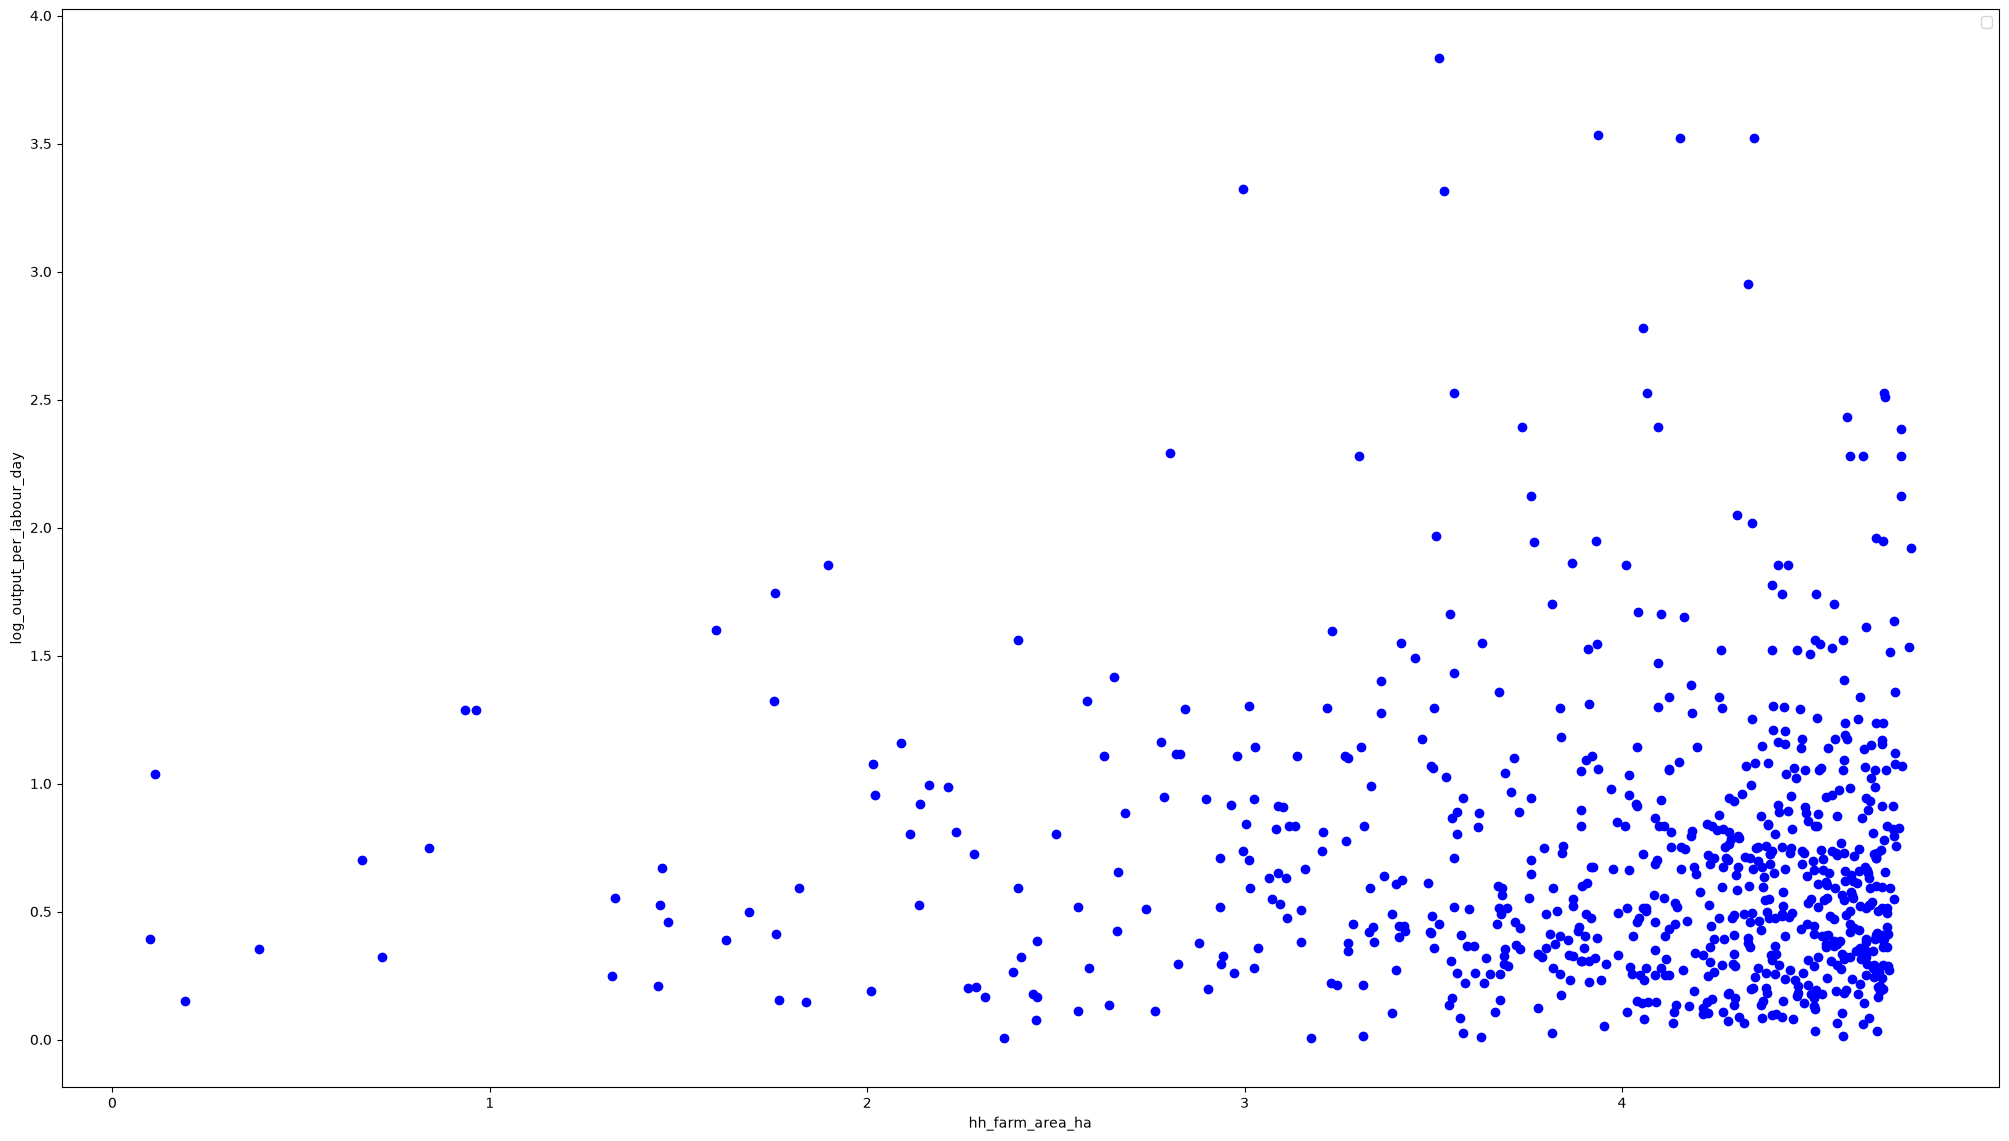

In [154]:
plt.scatter(df1["log_output_per_labour_day"],df1["hh_farm_area_ha"], color="blue")
plt.xlabel("hh_farm_area_ha")
plt.ylabel("log_output_per_labour_day")
plt.legend()
plt.show()

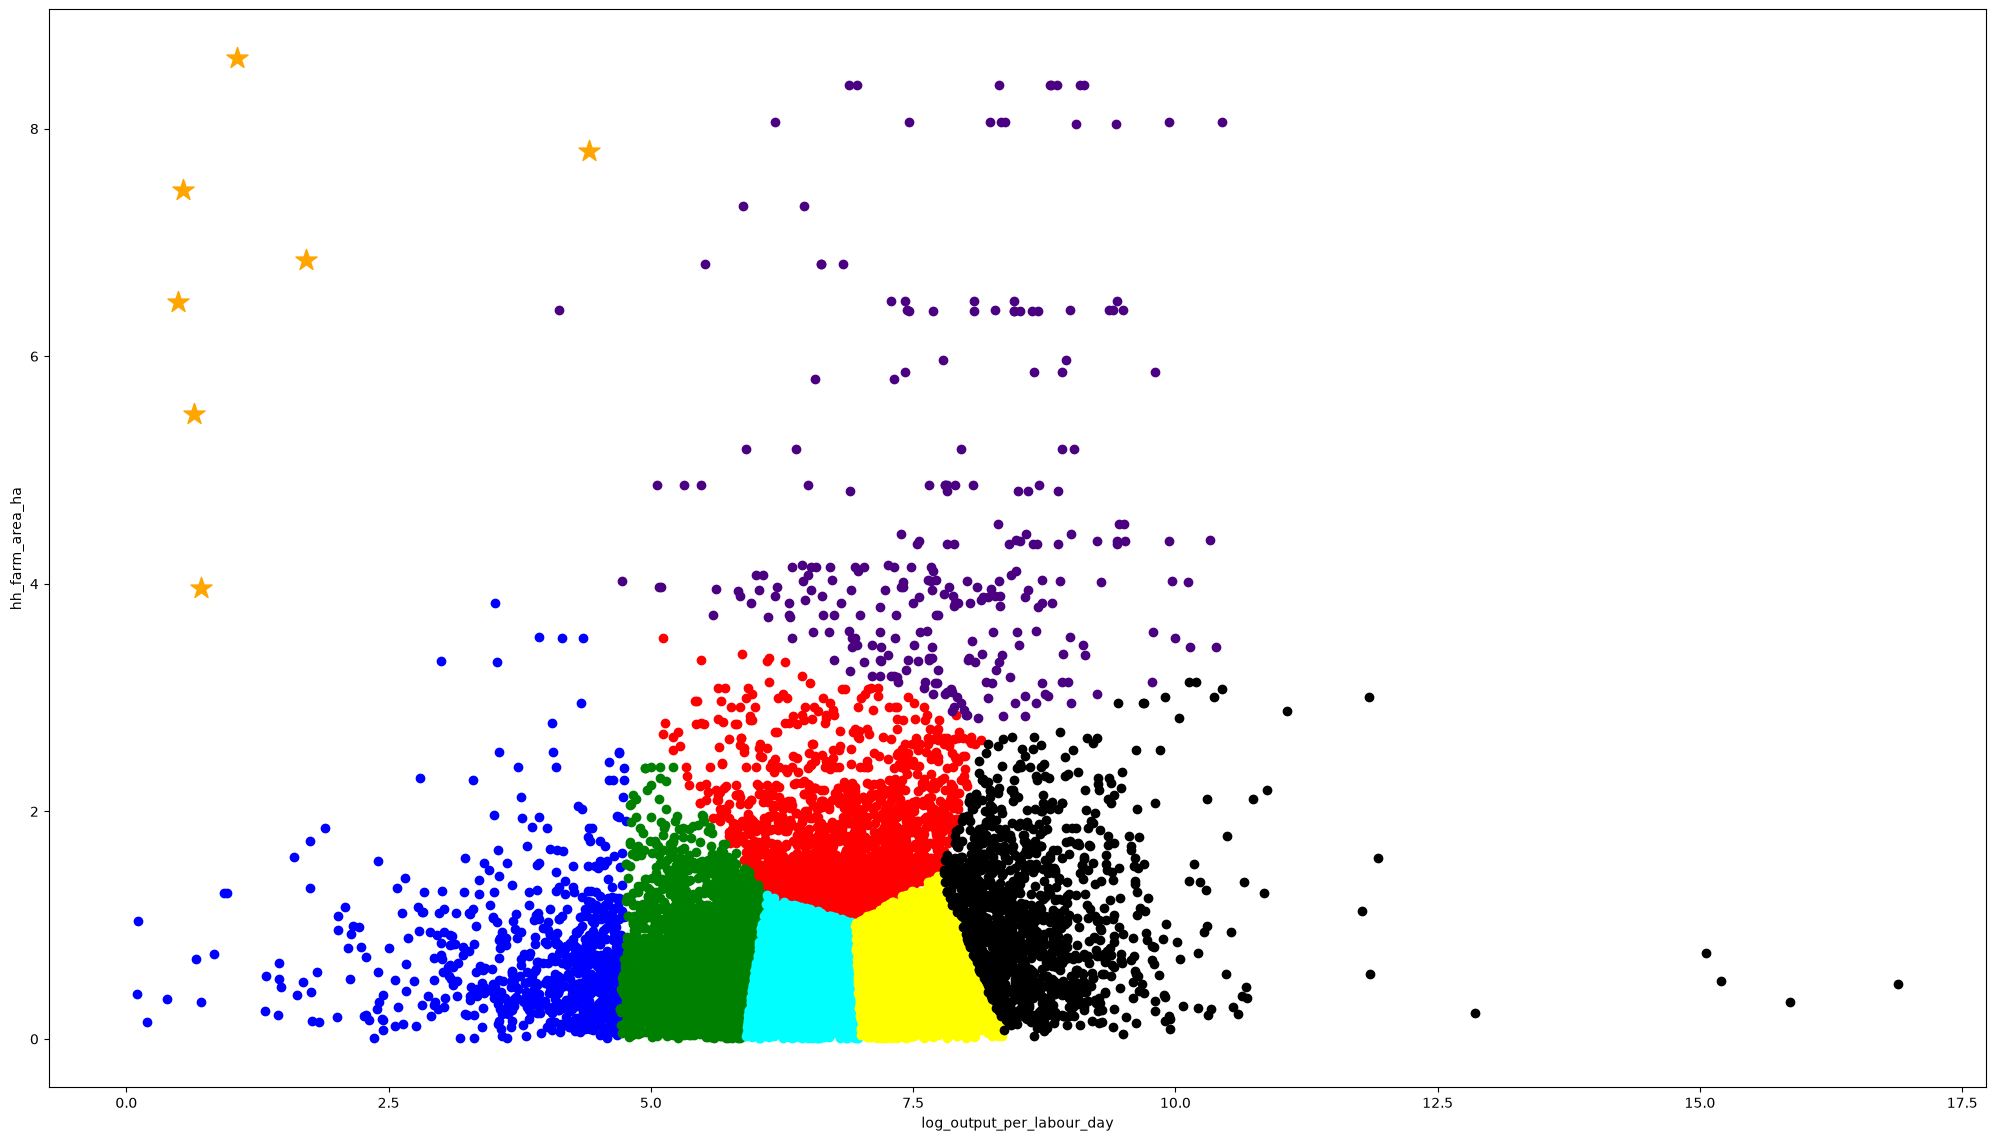

In [155]:
plt.scatter(df1["log_output_per_labour_day"],df1["hh_farm_area_ha"], color="blue")
plt.scatter(df2["log_output_per_labour_day"],df2["hh_farm_area_ha"], color="red")
plt.scatter(df3["log_output_per_labour_day"],df3["hh_farm_area_ha"], color="green")
plt.scatter(df4["log_output_per_labour_day"],df4["hh_farm_area_ha"], color="indigo")
plt.scatter(df5["log_output_per_labour_day"],df5["hh_farm_area_ha"], color="cyan")
plt.scatter(df6["log_output_per_labour_day"],df6["hh_farm_area_ha"], color="yellow")
plt.scatter(df7["log_output_per_labour_day"],df7["hh_farm_area_ha"], color="black")
plt.scatter(df8["log_output_per_labour_day"],df8["hh_farm_area_ha"], color="magenta")
plt.scatter(df9["log_output_per_labour_day"],df9["hh_farm_area_ha"], color="pink")
plt.scatter(df10["log_output_per_labour_day"],df10["hh_farm_area_ha"], color="gray")
plt.scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,1],color="orange", marker="*" , s=255.5)
plt.xlabel("log_output_per_labour_day")
plt.ylabel("hh_farm_area_ha")
# plt.legend()
plt.show()

***Modelling: Random Forest Analysis, Gradient Boosting, KNN, XGBoost***

***Reseting the Data Frame (Additional libraries also loaded at the top***)

In [156]:
target = "log_output_per_labour_day"      
drop_cols = [
    target, "output_per_labour_day_mwk", "output_value_mwk", "harvest_kg",
    "labour_days_total", "main_crop_by_value",
    "model_ready", "outlier_1pct", "all_crops_valued", "share_kg_conversion_factor",
    "case_id", "HHID", "ea_id", "gardenid", "plotid", "manager_pid", "survey_weight",
]

y3 = df_final[target]
X3 = df_final.drop(columns=drop_cols, errors="ignore")

In [157]:
print(X3.shape, y3.name)
print([c for c in X3.columns if "output" in c or "harvest" in c])
print(X3.shape, y3.name)
print([c for c in X3.columns if "output" in c or "harvest" in c])

(15326, 20) log_output_per_labour_day
[]
(15326, 20) log_output_per_labour_day
[]


In [158]:
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size= 0.25, random_state=42,
)

# 
print(X3_train.shape) 
print(X3_test.shape) 

(11494, 20)
(3832, 20)


***Modelling***

In [159]:
def decisionTree(depth):
    model = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=20, random_state=42)
    model.fit(X3_train, y3_train)

    pred_train = model.predict(X3_train)
    pred_test  = model.predict(X3_test)

    print(f"max_depth = {depth}")
    print(f"R² train: {r2_score(y3_train, pred_train):.3f} | R² test: {r2_score(y3_test, pred_test):.3f}")
    # print(f"RMSE test (log scale): {np.sqrt(mean_squared_error(y3_test, pred_test)):.3f}")
    # print(f"MAE test (log scale):  {mean_absolute_error(y3_test, pred_test):.3f}")
    return model

In [160]:
decisionTree(50)

max_depth = 50
R² train: 0.464 | R² test: 0.225


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",50
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes m

In [161]:
decisionTree(5)

max_depth = 5
R² train: 0.299 | R² test: 0.281


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes ma

In [162]:
decisionTree(100)

max_depth = 100
R² train: 0.464 | R² test: 0.225


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",100
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes 

In [163]:
decisionTree(42)

max_depth = 42
R² train: 0.464 | R² test: 0.225


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",42
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes m

*R² for Social Sciences & Human Behavior: Values as low as 0.3 to 0.5 (or even 0.2) can still be considered meaningful because human behavior is complex and messy.*

*Accuracy Score not applicable in this case due to the continous (Float datatype) of the dataset*

In [164]:
rf_model = RandomForestClassifier(
    n_estimators=100, # number of trees
    min_samples_leaf= 13,
    max_features='sqrt', # features considered per split(random in nature)
    max_depth =None, # let the three grow fully 
    bootstrap=True, # settles on bagging approach hence psample is picked with replacement
    oob_score=True,   
    random_state= 42, 
    n_jobs=-1, 
)

In [165]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    oob_score=True,        # this creates oob_score_
    bootstrap=True,        # the default; OOB needs it
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=42,
)
rf_model.fit(X3_train, y3_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.r2_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then 

In [166]:
# rf_model.fit(X3_train, y3_train) # model training
# rf_y_pred = rf_model.predict(X3_test) # prediction

In [167]:
models = {
    "Linear regression": LinearRegression(),
    "Ridge":             Ridge(alpha=1.0),
    "Lasso":             Lasso(alpha=0.01),
    "Random forest":     RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "Gradient boosting": HistGradientBoostingRegressor(random_state=42),   # fast, handles missing values
    "KNN":               KNeighborsRegressor(n_neighbors=15),             # needs scaled X
}

***Evaluation: Comparing the different models***

In [168]:
for name, model in models.items():
    model.fit(X3_train, y3_train)
    pred = model.predict(X3_test)
    rmse = np.sqrt(np.mean((y3_test - pred) ** 2))
    print(f"{name:20s} R² {r2_score(y3_test, pred):.3f} | RMSE {rmse:.3f} | MAE {mean_absolute_error(y3_test, pred):.3f}")

Linear regression    R² 0.198 | RMSE 1.050 | MAE 0.758
Ridge                R² 0.198 | RMSE 1.050 | MAE 0.758
Lasso                R² 0.240 | RMSE 1.022 | MAE 0.758
Random forest        R² 0.362 | RMSE 0.937 | MAE 0.682
Gradient boosting    R² 0.391 | RMSE 0.915 | MAE 0.666
KNN                  R² 0.279 | RMSE 0.996 | MAE 0.734


In [169]:
print(f" OOB Score: {rf_model.oob_score_:.3f}")

 OOB Score: 0.360


***Modelling: XGBoost***

In [170]:
df_final.head()

,hh_farm_area_ha,small_scale,n_crops,irrigated,organic_fert_used,inorganic_fert_used,inorganic_fert_kg,pesticide_used,labour_days_family,labour_days_hired,...,labour_days_free,plot_dist_household_km,hh_dist_road_km,hh_dist_market_km,hh_dist_admarc_km,hh_dist_popcenter_km,pop_density,rain_annual_avg_mm,rain_2019_mm,log_output_per_labour_day
0,0.453248,0,1.0,0,0,1,25.0,0,30.0,0.0,...,0.0,0.2,3.6,4.1,12.8,4.1,610.0,1007.0,1158.0,7.699610
1,0.655591,0,2.0,0,0,1,150.0,0,140.0,0.0,...,0.0,0.1,3.6,4.1,12.8,4.1,610.0,1007.0,1158.0,7.096012
2,0.655591,0,1.0,0,0,0,0.0,0,48.0,0.0,...,0.0,0.1,3.6,4.1,12.8,4.1,610.0,1007.0,1158.0,5.443471
3,0.485623,0,2.0,0,0,1,20.0,0,7.0,0.0,...,0.0,0.0,3.6,4.1,12.8,4.1,610.0,1007.0,1158.0,8.341610
4,1.157402,0,1.0,0,0,1,100.0,0,24.0,0.0,...,0.0,0.0,3.6,4.1,12.8,4.1,610.0,1007.0,1158.0,8.328218


In [171]:
counts = df_final['inorganic_fert_used'].value_counts().sort_index()
counts

inorganic_fert_used
0    7527
1    7799
Name: count, dtype: int64

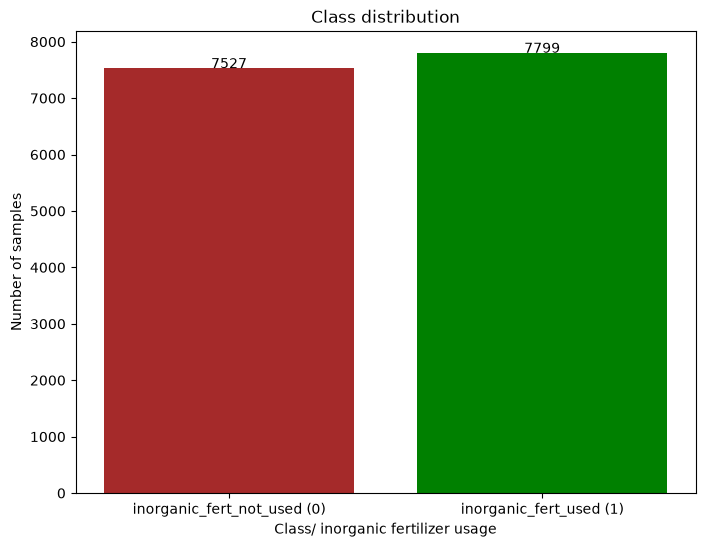

In [172]:
plt.figure(figsize=(8,6)) # usually manipulates the size
plt.bar(['inorganic_fert_not_used (0)','inorganic_fert_used (1)'], counts.values, color=['brown', 'green'])
plt.title("Class distribution")
plt.ylabel('Number of samples')
plt.xlabel('Class/ inorganic fertilizer usage')

for i, v in enumerate(counts.values):
    plt.text(i,v + 5, str(v), ha='center')

plt.show()

***Setting the Dataframe to use***

In [173]:
X4 = df_final.drop(['inorganic_fert_used'], axis = 1) # independent variable
y4 = df_final['inorganic_fert_used']

In [174]:
X4_train, X4_test, y4_train, y4_test = train_test_split(
    X4, y4,
    test_size=0.3, 
    random_state=42, 
    stratify= y4 # it will retain a constant proportion when splitting the two classes
)

*Modelling*

In [175]:
n_estimators = 100 
learning_rate = 0.1 # ranges from 0.01 to 0.3
max_depth = 2

In [176]:
xgb_model = xgb.XGBClassifier(
    n_estimators = n_estimators, 
    learning_rate = learning_rate,
    max_depth = max_depth, 
    random_state=42, 
    eval_metric="logloss"
)

In [177]:
# xgb_model = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6,
#                          subsample=0.8, colsample_bytree=0.8, random_state=42)
# xgb_model.fit(X4_train, y4_train)
# xgb_y_pred = xgb_model.predict(X4_test)

In [178]:
xgb_model.fit(
    X4_train, y4_train,
    eval_set=[(X4_train, y4_train), (X4_test, y4_test)], 
    verbose=False
) # training the model

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [179]:
# plt.figure(figsize=(20, 10))
# plot_tree(xgb_model, feature_names=X4_train.columns, max_depth=3,   # show top 3 levels only
#           filled=True, rounded=True, fontsize=9)
# plt.show()

In [180]:
y_pred = xgb_model.predict(X4_test) # prediction
y_proba = xgb_model.predict_proba(X4_test)[:,1]

In [181]:
y_pred

array([1, 1, 1, ..., 0, 1, 0], shape=(4598,))

In [182]:
y_proba

array([0.99954885, 0.9996094 , 0.9996363 , ..., 0.01384761, 0.9994923 ,
       0.01384076], shape=(4598,), dtype=float32)

# ***Evaluation***

In [183]:
accuracy  = accuracy_score(y4_test, y_pred)
log_loss_output = log_loss(y4_test, y_proba)

print(f"ACCURACY: {(accuracy *100):.2f}%")
print(f"log_loss: {(log_loss_output):.2f}")

ACCURACY: 99.52%
log_loss: 0.02


In [184]:
print(classification_report(y4_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      1.00      2258
           1       1.00      0.99      1.00      2340

    accuracy                           1.00      4598
   macro avg       1.00      1.00      1.00      4598
weighted avg       1.00      1.00      1.00      4598



In [185]:
# loss cruves f the train and text per boosting round
results = xgb_model.evals_result()
train_curve = results["validation_0"]["logloss"]
test_curve = results["validation_1"]["logloss"]

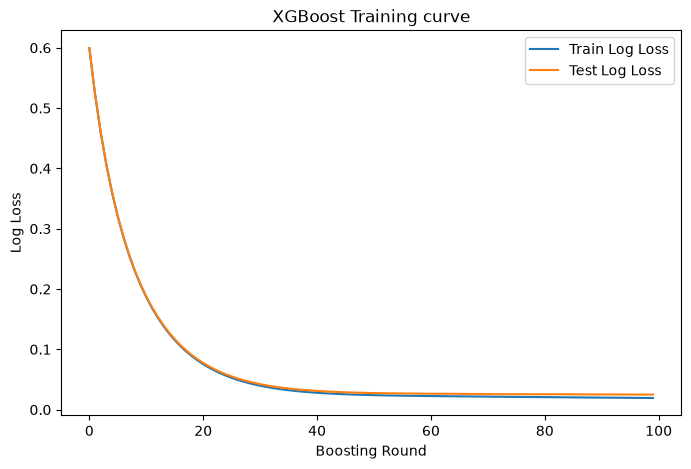

In [186]:
plt.figure(figsize=(8,5))
plt.plot(train_curve, label="Train Log Loss")
plt.plot(test_curve, label="Test Log Loss")
plt.xlabel("Boosting Round")
plt.ylabel("Log Loss")
plt.title("XGBoost Training curve")
plt.legend()
plt.show()

*Feature importance*

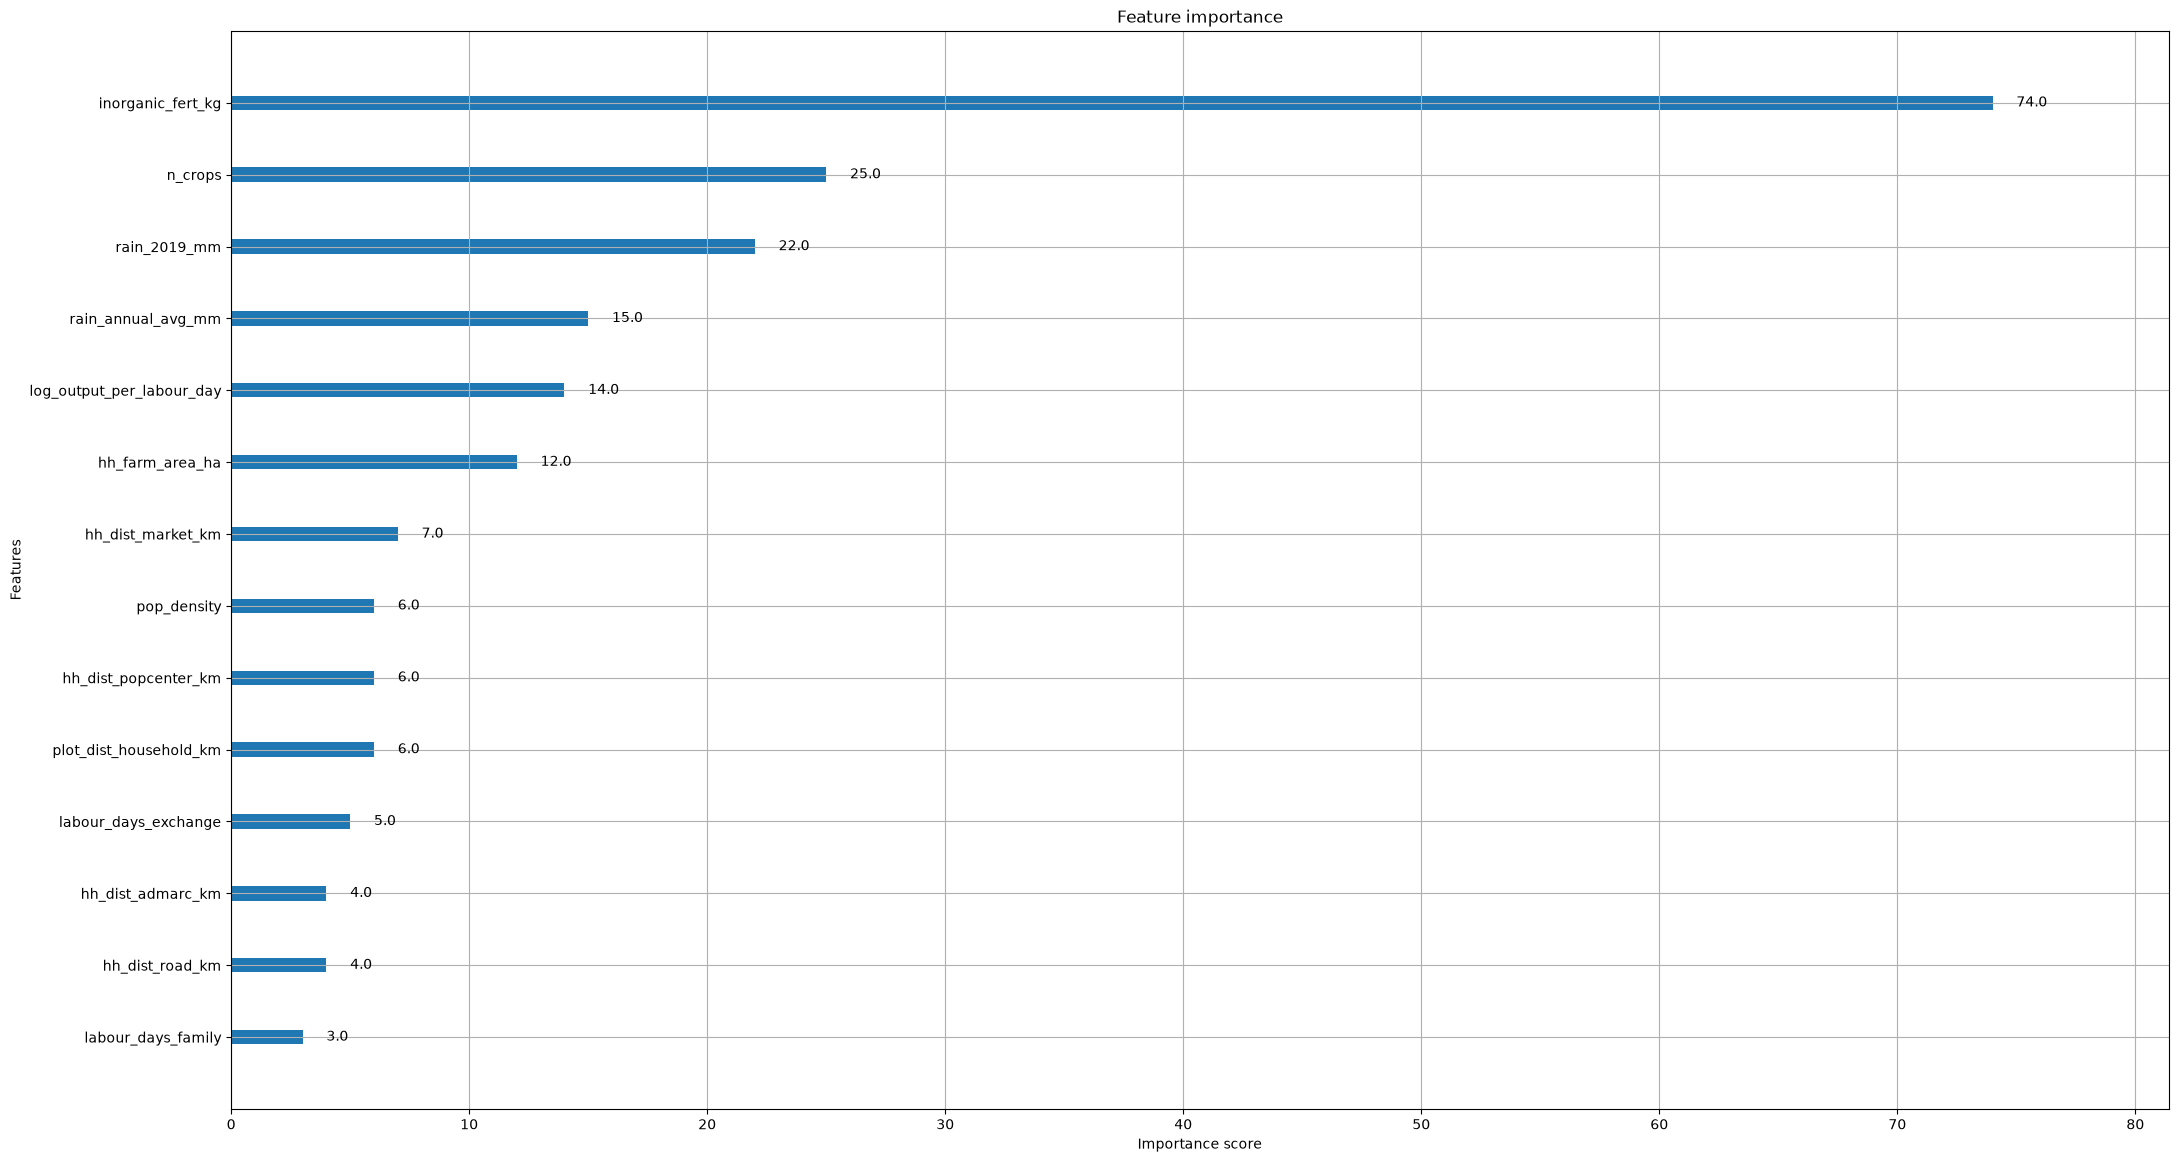

In [187]:
# xgb.plot_tree(xgb_model)
xgb.plot_importance(xgb_model)
plt.rcParams['figure.figsize'] = [25,14] 
plt.show()

In [188]:
df_final.to_csv('Data\\malawi_ihs5_sdg231_plot_dataset_cleaned.csv', index=False)

# ***Summary***